In [23]:
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import pathlib
import pandas as pd
from PIL import Image
import os


from tensorflow import keras
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input, Dense, concatenate, Conv2D, MaxPooling2D, UpSampling2D
import tensorboard
from tensorflow.keras.utils import load_img, img_to_array
%matplotlib inline

In [9]:
#Time series data
#Tokenizing (using packages to map each word to a number), injected to the algorithm
#Embedding  

#Load MNIST dataset 
#Labels are omitted with linear units (Gaussian Distribution) since autoencoders are unsupervised
#(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()
#dataPath = next(path for path, dirs, files in os.walk(dataPath) if len(dirs)>1)
#dPath=pathlib.Path(dataPath)

#(x_train, _), (x_test, _) = keras.datasets.mnist.load_data()
img_size = 28

x_trainDir = [r'C:\Users\User\Documents\Content Data Science\Dataset Livrable 2']
x_testDir = [r'C:\Users\User\Documents\Content Data Science\Dataset Livrable 2']

def load_images_from_directories(dir_list, target_size=(img_size, img_size)):
    images = []
    for directory in dir_list:
        path = pathlib.Path(directory)
        if not path.exists():
            print(f'Warning: Directory {directory} does not exist. Moving on...')
            continue
        image_extensions = {'.png', '.jpg', '.jpeg', '.bmp', '.tiff'}
        for img_path in path.glob('**/*.*'):
            if img_path.suffix.lower() in image_extensions:
                try:
                    img = load_img(img_path)
                    img = img.resize(target_size)
                    if img.mode in ('RGBA', 'LA') or (img.mode == 'p' and 'transparency' in img.info):
                        img = img.convert('RGBA')
                        background = Image.new('RGB', img.size, (255, 255, 255))
                        background.paste(img, mask=img.split()[3])
                        img_rgb = background
                    else:
                        img_rgb=img.convert('RGB')
                        
                    img_array = img_to_array(img_rgb)
                    images.append(img_array)
                except Exception as e:
                    print(f'Error loading {img_path}: {e}')
    if len(images) == 0:
        raise ValueError('No images found in the specified directories! Please check your paths. ')
    data = np.array(images, dtype='float32') / 255.0
    return data



print('Loading training images ...')
x_train= load_images_from_directories(x_trainDir)
#x_train = x_train.astype('float32')/255.0
#x_train = np.reshape(x_train, (len(x_train), 28, 28, 1))

print('Loading testing images ...')
x_test= load_images_from_directories(x_testDir)
#x_test = x_test.astype('float32')/255.0
#x_test = np.reshape(x_test, (len(x_test), 28, 28, 1))


print('Training Shape: ', x_train.shape, 'Min: ', x_train.min(), 'Max', x_train.max(), 'Mean Pixel', x_train.mean())
print('Testing Shape: ', x_test.shape, 'Min: ', x_test.min(), 'Max', x_test.max())








Loading training images ...
Loading testing images ...
Training Shape:  (148, 28, 28, 3) Min:  0.0 Max 1.0 Mean Pixel 0.4612651
Testing Shape:  (148, 28, 28, 3) Min:  0.0 Max 1.0


In [10]:
#Dataset Loader and Preprocessor
#x_train = x_train.astype('float32')/255.0
#x_test = x_test.astype('float32')/255.0

#x_train = np.reshape(x_train, (len(x_train), 28, 28, 1))
#x_test = np.reshape(x_test, (len(x_test), 28, 28, 1))


print('Training Shape: ', x_train.shape)
print('Testing Shape: ', x_test.shape)

Training Shape:  (148, 28, 28, 3)
Testing Shape:  (148, 28, 28, 3)


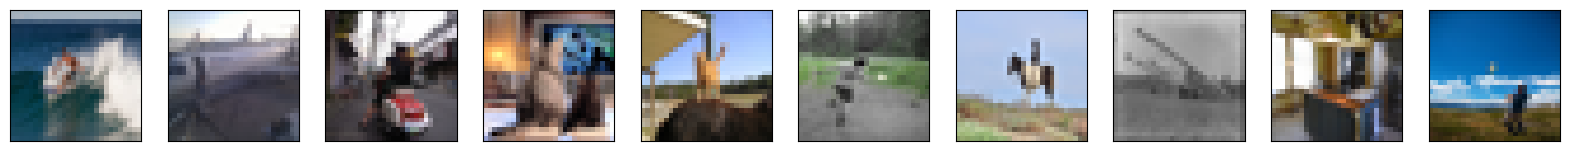

In [11]:

#Visualization Function 
#Function displays the first and images from dataset X in grayscale
def display_image(X, n=10):
    plt.figure(figsize=(20,2))
    n = min(n, len(X))
    for i in range(n):
        ax = plt.subplot(1, n, i+1)
        plt.imshow(X[i])
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)
    plt.show()

def display_comparison(original, noisy, denoised, n=5):
    plt.figure(figsize=(n*2, 6))
    n = min(n, len(original))
    for i in range(n):
        ax = plt.subplot(3, n, i+1)
        plt.imshow(original[i])
        plt.title('Clean' if i==0 else'')
        ax.axis('off')

        ax = plt.subplot(3, n, i+1+n)
        plt.imshow(np.clip(noisy[i], 0.0, 1.0))
        plt.title('Noise' if i==0 else '')
        ax.axis('off')

        ax=plt.subplot(3, n, i+1+2*n)
        plt.imshow(denoised[i])
        plt.title('Denoised' if i==0 else '')
        ax.axis('off')
    plt.tight_layout()
    plt.show()





# Displays the sample clean images from the given dataset
display_image(x_train, n=10)



Original Clean Images: 


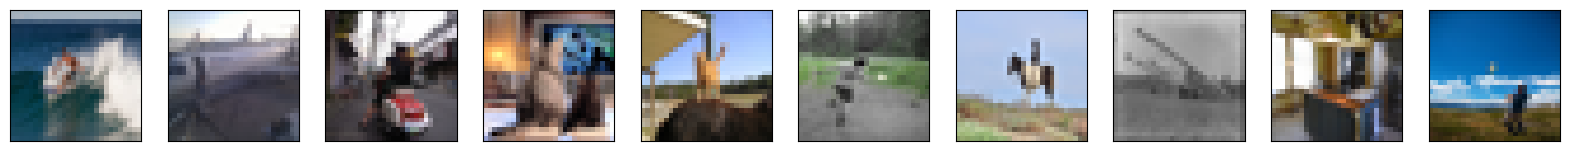

Synthetically Noisy Input: 


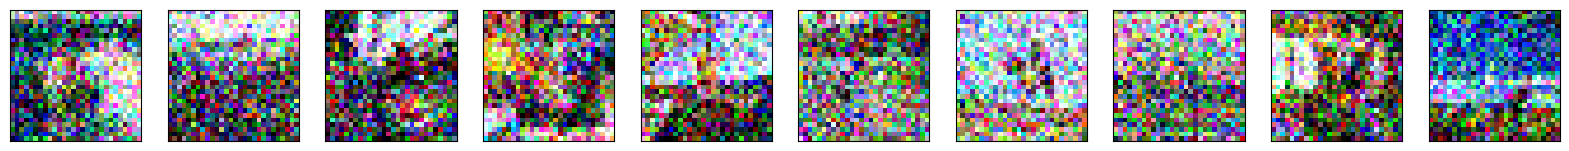

In [12]:
# Noise Generation (Synthetic Noise Generation) 
# Adds Gaussian noise to the dataset to simulate real-world noises (artifacts)

noise_factor = 0.3

#Add Zero-mean normal distribution noise
x_train_noise = x_train + noise_factor*np.random.normal(loc=0.0, scale=1.0, size=x_train.shape)
x_test_noise = x_test + noise_factor*np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)

#Clip values to maintain the valid pixel range between 0.0, 1.0 -> [0.0, 1.0]
x_train_noise = np.clip(x_train_noise, 0.0, 1.0)
x_test_noise = np.clip(x_test_noise, 0.0, 1.0)

#Displaying clean versus noisy comparisions 
print('Original Clean Images: ')
display_image(x_train, n=10)

print('Synthetically Noisy Input: ')
display_image(x_train_noise, n=10)



In [13]:
# Using Hyperparameters and Model Configuration 

#Image width and height in pixel
IMG_SIZE = 28

#Number of trianing epochs
NB_EPOCHS_DENOISE = 50

#Batch size for mini-batch SGD
BATCH_SIZE = 64

#Target Path for model saving
SAV_MODEL_DENOISE = 'rgb_unet_denoiser.keras'

callback = [
    keras.callbacks.EarlyStopping(
        monitor = 'val_loss',
        mode = 'min',
        min_delta = 1e-4,
        patience = 10,
        verbose = 1,
        restore_best_weights = True
    ),
    keras.callbacks.ModelCheckpoint(
        filepath = SAV_MODEL_DENOISE, 
        monitor = 'val_loss',
        mode= 'min',
        save_best_only = True,
        verbose = 1
    ),
    keras.callbacks.TensorBoard(log_dir='/temp/tb_logs', histogram_freq = 0)
]

In [20]:
# Constructing the Convolutional Denoising Autoencoder 
# Constructs the encoder and decoder using ...
#........ Convolutional Sampling Operations
#........ Spatial Sampling Operations

# Encoder - section
input_img = Input(shape=(img_size, img_size,3), name='encoder_input')

# Converting block 1 (28, 28, 3) to (28, 28, 32), then to (14, 14, 32)
c1 = Conv2D(32, (3,3), activation='relu', padding='same')(input_img)
c1 = Conv2D(32, (3,3), activation='relu', padding='same')(c1)
p1 = MaxPooling2D((2, 2), padding='same')(c1)

#converting block 2 (14,14,32) to (14,14,32) and then to (7,7,32)
c2 = Conv2D(64, (3,3), activation = 'relu', padding = 'same')(p1)
c2 = Conv2D(64, (3,3), activation = 'relu', padding = 'same')(c2)
p2 = MaxPooling2D((2,2), padding='same')(c2)

# Bottleneck 
b = Conv2D(128, (3, 3), activation = 'relu', padding = 'same')(p2)
b = Conv2D(128, (3, 3), activation = 'relu', padding = 'same')(b)

# Decoder - section 
# Converts Block 1 (7,7,32) to (7,7,32) and then to (14,14,32)
u1 = UpSampling2D((2, 2))(b)
m1 = concatenate([u1, c2], axis = -1) # Merge 1
d1 = Conv2D(64, (3,3), activation='relu', padding='same')(m1)
d1 = Conv2D(64, (3,3), activation='relu', padding='same')(d1)


# Reverse (DeConv) Block 2 (14,14,32) to (14,14,32) and then to (28,28,32)
u2 = UpSampling2D((2,2))(d1)
m2 = concatenate([u2, c1], axis = -1) # Merge 2
d2 = Conv2D(32, (3,3), activation='relu', padding='same')(m2)
d2 = Conv2D(32, (3,3), activation='relu', padding='same')(d2)



# Reconcstruction Layer (28,28, 32) constructs to (28,28,3)
decoded = Conv2D(3, (3,3), activation = 'sigmoid', padding='same')(d2)

#Instantiate and Compile full autoencoder Model
autoencoder = Model(inputs=input_img, outputs = decoded, name = 'rgb_unet_denoiser')
def sharpness_loss(y_true, y_pred):
    mse = tf.reduce_mean(tf.square(y_true - y_pred))
    ssim = 1.0 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val = 1.0))
    # Blends pixel accuracy with structural similarity to keep crisp edges
    return mse + 0.4* ssim
#Optimizer
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)
autoencoder.compile(optimizer=optimizer, loss = sharpness_loss)
autoencoder.summary()


Model: "rgb_unet_denoiser"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 28, 28, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_28 (Conv2D)  │ (None, 28, 28,    │        896 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_29 (Conv2D)  │ (None, 28, 28,    │      9,248 │ conv2d_28[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 14, 14,    │          0 │ conv2d_29[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 14, 14,    │     18,496 │ max_pooling2d_6[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 14, 14,    │     36,928 │ conv2d_30[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 7, 7, 64)  │          0 │ conv2d_31[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 7, 7, 128) │     73,856 │ max_pooling2d_7[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 7, 7, 128) │    147,584 │ conv2d_32[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_5     │ (None, 14, 14,    │          0 │ conv2d_33[0][0]   │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 14, 14,    │          0 │ up_sampling2d_5[… │
│ (Concatenate)       │ 192)              │            │ conv2d_31[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_34 (Conv2D)  │ (None, 14, 14,    │    110,656 │ concatenate_4[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_35 (Conv2D)  │ (None, 14, 14,    │     36,928 │ conv2d_34[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_6     │ (None, 28, 28,    │          0 │ conv2d_35[0][0]   │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_5       │ (None, 28, 28,    │          0 │ up_sampling2d_6[… │
│ (Concatenate)       │ 96)               │            │ conv2d_29[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_36 (Conv2D)  │ (None, 28, 28,    │     27,680 │ concatenate_5[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_37 (Conv2D)  │ (None, 28, 28,    │      9,248 │ conv2d_36[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 472,387 (1.80 MB)

 Trainable params: 472,387 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - loss: 0.4213   WARNING:tensorflow:5 out of the last 301 calls to <function TensorFlowTrainer._make_function.<locals>.one_step_on_data at 0x0000021A9439DF30> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.

Epoch 1: val_loss did not improve from 0.01272
3/3 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - loss: 0.4213 - val_loss: 0.4185
Epoch 2/50
2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - loss: 0.4176
Epoch 2: val_loss did not improve from 0.012

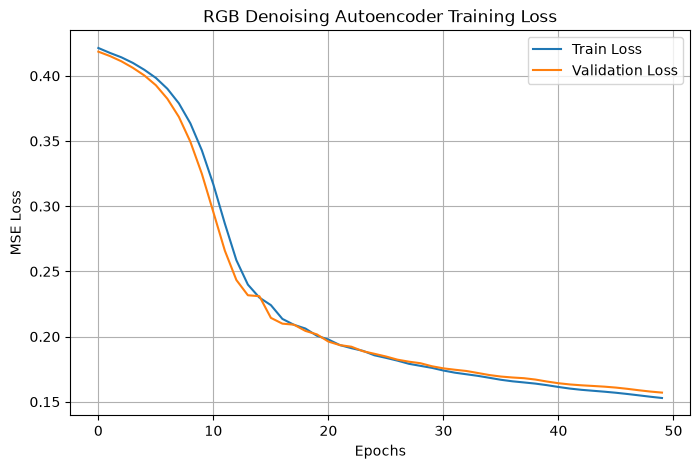

In [21]:
# Training and Evaluation 
# Training the autoencoder to map noisy inputs to clean ground-truth images

#load_ext TensorBoard

# Fit the autoencoder model
history = autoencoder.fit(x_train_noise,
                          x_train, 
                          epochs=NB_EPOCHS_DENOISE,
                          batch_size = BATCH_SIZE,
                          shuffle = True,
                          validation_data = (x_test_noise, x_test),
                          callbacks = callback)

#Plot trianing and validation loss curves 
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label = 'Validation Loss')
plt.title('RGB Denoising Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)
plt.show()

Model Successfuly Saved to rgb_unet_denoiser.keras
3/5 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step WARNING:tensorflow:5 out of the last 11 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x0000021A982DF3D0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 129ms/step
QUantitative Denoising Performance
Mean Squared Error (MSE): 0.0167
Average PSNR: 18.04 dB
Average SSIM: 0.6491
Noisy Input Images (Test Set): 


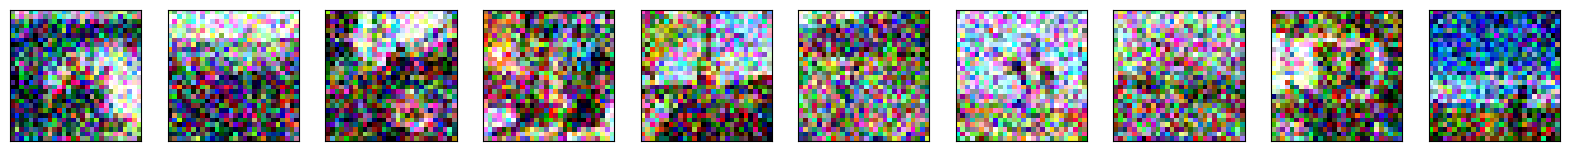

Denoised Reconstruct Outputs (Model Predictions): 


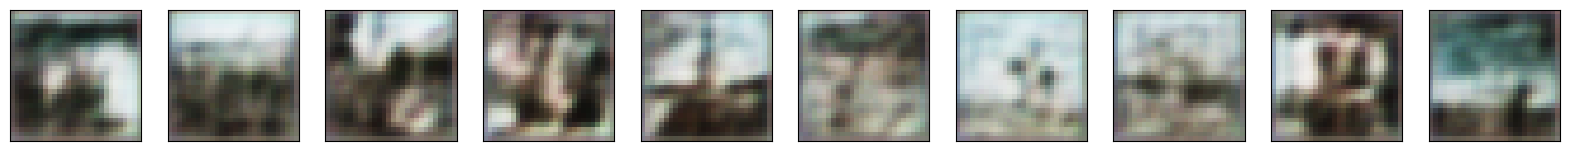

Overall Comparison: CLean, Noisy, and Denoised


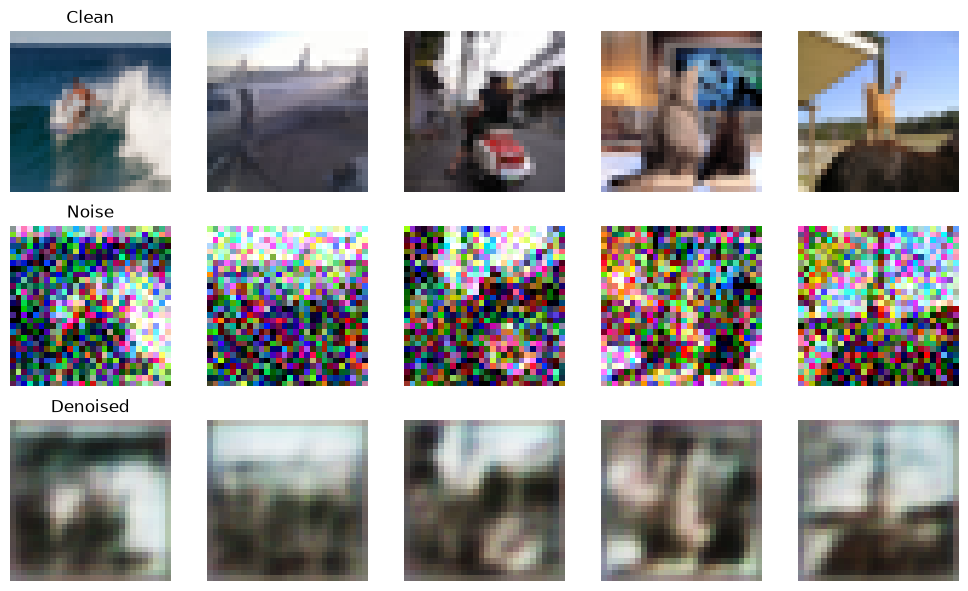

In [22]:
# Model Saving, Inference & Evaluation 
# Saves the trained weights and test the reconstruction quality on unseen noisy images.

# Save the model artifact locally 

autoencoder.save(SAV_MODEL_DENOISE)
print(f'Model Successfuly Saved to {SAV_MODEL_DENOISE}')

# Generate denoised outputs on test dataset
decoded_imgs = autoencoder.predict(x_test_noise)

#Quantitative Metrics Evaluation
y_true = tf.convert_to_tensor(x_test, dtype=tf.float32)
y_pred = tf.convert_to_tensor(decoded_imgs, dtype=tf.float32)

mse = tf.reduce_mean(tf.square(y_true - y_pred))
psnr = tf.image.psnr(y_true, y_pred, max_val=1.0)
mean_psnr = tf.reduce_mean(psnr)
ssim = tf.image.ssim(y_true, y_pred, max_val=1.0)
mean_ssim = tf.reduce_mean(ssim)

print('QUantitative Denoising Performance')
print(f'Mean Squared Error (MSE): {mse.numpy():.4f}')
print(f'Average PSNR: {mean_psnr.numpy():.2f} dB')
print(f'Average SSIM: {mean_ssim.numpy():.4f}')

# loaded_model = load_model('rgb_unet_denoiser.keras', custom_objects={'sharpness_loss': sharpness_loss})
# print('Model successful loaded from disk! ')
# new_decoded_imgs = loaded_model.predict(x_test_noise)

#visualize qualitative results 
print('Noisy Input Images (Test Set): ')
display_image(x_test_noise, n=10)

print('Denoised Reconstruct Outputs (Model Predictions): ')
display_image(decoded_imgs, n=10)

print ('Overall Comparison: CLean, Noisy, and Denoised')
display_comparison(x_test, x_test_noise, decoded_imgs, n=5)
